# DuckDB Masterclass — Capítulo 07
## Macros SQL escalares, de tabela e UDFs Python

**Edição didática para estudo autônomo e publicação**  
**Contexto:** Operations Analytics e telecomunicações | **Dados:** sintéticos  
**Roteiro:** hipótese → executar → validar → interpretar → desafio → autoavaliação.

> Execute as células **de cima para baixo** em um kernel limpo. Resultados reais só devem ser salvos depois da execução no seu ambiente. Não publique dados privados, credenciais ou caminhos absolutos.

## 07.1 — Objetivos e diagnóstico

- Criar e testar macro escalar com divisão por zero.
- Criar macro de tabela reutilizável.
- Comparar macro SQL e função Python registrada.
- Reconhecer limites de desempenho e efeitos colaterais.

**Pergunta de partida:** que risco operacional aparece quando utilizamos essa tecnologia de forma inadequada?

## 07.2 — Conceitos essenciais

Macros são expressões SQL parametrizadas; não equivalem automaticamente a chamadas de Python por linha. Funções Python registradas (UDFs) executam código fora da linguagem SQL e devem ser avaliadas quanto a tipos, tratamento de nulos, efeitos e custo.

### 🗺️ Modelo visual — Macros SQL escalares, de tabela e UDFs Python

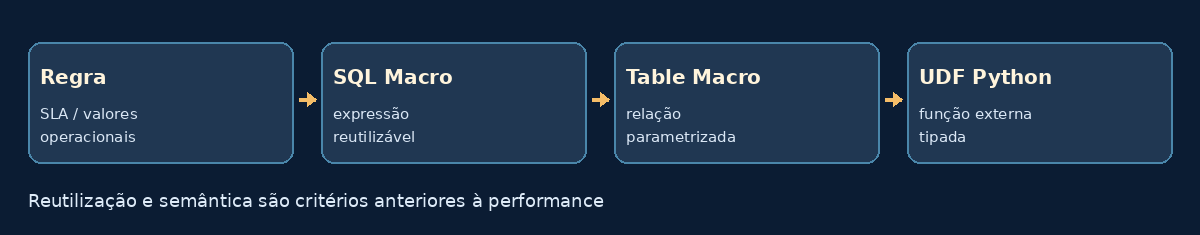

*Ilustração esquemática; não representa medição experimental.*

## 07.3 — Preparação e pré-requisitos

- Kernel recomendado: **Python (DuckDB Masterclass)**.
- Instale dependências ausentes no seu ambiente, fora do fluxo dos laboratórios.
- Cada arquivo produzido é sintético e deve ser salvo em pasta temporária ou `dados/` (ignorada pelo Git).
- Não execute instalação de extensões externas sem entender a necessidade, conectividade e eventuais custos.

## 07.4 — 🔬 Preparar conexão e macro escalar

**Hipótese / tarefa:** Calcular percentuais com proteção contra divisão por zero.

In [ ]:
import duckdb
from IPython.display import display
con = duckdb.connect(':memory:')
print('DuckDB:', duckdb.__version__)
con.execute('CREATE MACRO percentual(parte,total) AS 100.0*parte/NULLIF(total,0)')
res=con.execute('SELECT percentual(25,100) AS pct, percentual(2,0) AS sem_base').df()
display(res)
assert float(res.loc[0,'pct'])==25.0
assert res.loc[0,'sem_base'] is None or str(res.loc[0,'sem_base']) in ('<NA>','nan') or __import__('pandas').isna(res.loc[0,'sem_base'])

**Interpretação e limite:** `NULLIF` evita divisão por zero; `NULL` exige interpretação.

## 07.5 — 🔬 Macro de tabela

**Hipótese / tarefa:** Retornar somente valores acima de um parâmetro.

In [ ]:
con.execute('CREATE MACRO numeros_acima(limite) AS TABLE SELECT i FROM range(10) t(i) WHERE i > limite')
res=con.execute('SELECT * FROM numeros_acima(6) ORDER BY i').df()
display(res)
assert res['i'].tolist()==[7,8,9]

**Interpretação e limite:** Macros tabulares produzem relações consultáveis.

## 07.6 — 🔬 UDF Python simples

**Hipótese / tarefa:** Registrar função numérica determinística e comparar com SQL.

In [ ]:
def dobrar_python(valor:int)->int:
    return valor*2
con.create_function('dobrar_python', dobrar_python, ['INTEGER'], 'INTEGER')
res=con.execute('SELECT dobrar_python(12) AS python_udf, 12*2 AS sql_nativo').df()
display(res)
assert int(res.loc[0,'python_udf'])==int(res.loc[0,'sql_nativo'])==24

**Interpretação e limite:** Uma UDF em Python pode ter overhead; não estimamos aqui ganho/perda.

## 07.7 — 🔬 Validação de casos extremos

**Hipótese / tarefa:** Verificar resultados positivos, nulos e interpretação operacional.

In [ ]:
res=con.execute("""SELECT percentual(0,100) AS sem_parte,
 percentual(100,100) AS total, percentual(1,0) IS NULL AS base_invalida""").df()
display(res)
assert bool(res.loc[0,'base_invalida'])
assert float(res.loc[0,'sem_parte'])==0

**Interpretação e limite:** Resultado correto não valida escalabilidade.

## 07.8 — 🎯 Desafio profissional

Para calcular percentual de SLA por equipamento em diferentes consultas, quando escolher macro SQL, UDF Python ou expressão inline?

**Critério de aceite:** apresentar a consulta ou procedimento, verificar uma hipótese e explicar pelo menos uma limitação. Resolva antes de consultar a referência abaixo.

### 🧠 Solução comentada / critérios de conferência

Prefira macro quando a lógica é expressável em SQL e reutilizada. UDF Python é justificável para lógica externa; teste tipos, nulos e efeitos.

## 07.9 — Autoavaliação

1. Explique o recurso sem reproduzir o código.
2. O que foi efetivamente demonstrado?
3. Que caso-limite poderia invalidar a interpretação?
4. Como validar a resposta com `assert`, SQL ou inspeção do plano?
5. Quando aplicaria isso em operações de telecomunicações?

**Gabarito orientador:** consulte a solução comentada do desafio e compare sua resposta com os resultados efetivamente observados; não conclua propriedades de performance ou produção sem evidência.

## 07.10 — Referências, reprodução e publicação

- [CREATE MACRO](https://duckdb.org/docs/stable/sql/statements/create_macro)
- [Python Function API](https://duckdb.org/docs/stable/clients/python/function.html)

**Notas de engenharia:** Não comparar velocidade sem benchmark controlado.

**Checklist editorial:** executar `Restart & Run All` quando aplicável; salvar saídas úteis; revisar integridade, privacidade, dependências e gráficos antes do `git add`.